In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [1]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [4]:
df_allreco = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_allreco.csv')
df_alltruth = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_alltruth.csv')

Process PYTHIA6+GEANT

In [5]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [6]:
df_match.shape[0]

1549662

In [7]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [8]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

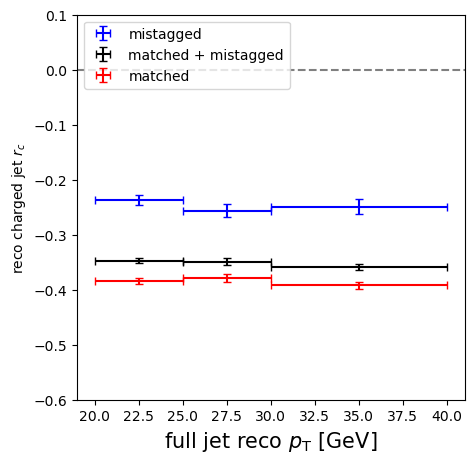

In [9]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [10]:
rc_allfake_bs_vs_pts_array

[-0.2508636655114501,
 -0.23746217106920509,
 -0.2560752775907103,
 -0.24927989803212855,
 -0.27888188083352095]

In [11]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [12]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [13]:
b_fake_array

[array([0.62543183, 0.37456817]),
 array([0.61873109, 0.38126891]),
 array([0.62803764, 0.37196236]),
 array([0.62463995, 0.37536005]),
 array([0.63944094, 0.36055906])]

In [14]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [15]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

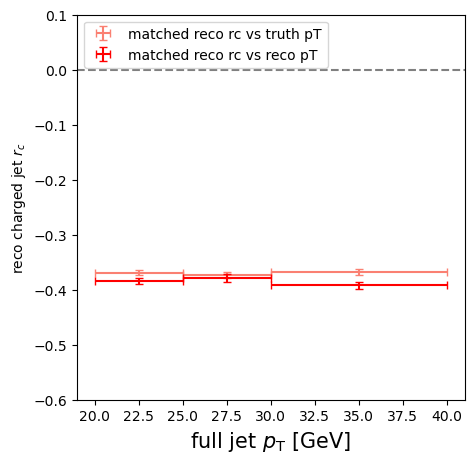

In [16]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [17]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69372956 0.30627044]
[0.69209685 0.30790315]
[0.68951847 0.31048153]
[0.6959566 0.3040434]
[0.69001344 0.30998656]


In [18]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_990155/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [19]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.30168861, 0.25406766, 0.24354468, 0.23288556, 0.23430428])

Process data

In [20]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [21]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [22]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [23]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [24]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [25]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [26]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[240054.46835537 119895.72639575]
[489.95353694 346.25962282]
1
[72379. 38554.]
[54940.38141325 27808.13102107]
[234.39364627 166.75770153]
2
[16450.  8688.]
[12605.01148036  6410.76226738]
[112.27204229  80.06723592]
3
[4758. 2573.]
[3691.56219204 1932.15378035]
[60.75822736 43.95627123]
4
[334. 153.]
[261.0358349  111.85798189]
[16.15660345 10.57629339]


In [27]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [28]:
reweight_array

[array([0.96134038, 1.08756745]),
 array([0.95932244, 1.09143397]),
 array([0.961354  , 1.08582516]),
 array([0.94320187, 1.13001115]),
 array([1.01451249, 0.96769598])]

Reweight PYTHIA6+GEANT

In [32]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 62.63618029153809
anomaly reco pT: 72.52834643481873
anomaly reco pT: 69.20280354409849
anomaly reco pT: 65.41875767926956
anomaly reco pT: 60.08826616308812
anomaly reco pT: 60.40517134190412
anomaly reco pT: 63.5635618687876
anomaly reco pT: 61.751493441117056
anomaly reco pT: 62.34646747658196
anomaly reco pT: 60.70405679752255
anomaly reco pT: 60.19295906829795
anomaly reco pT: 60.10291529624253
anomaly reco pT: 60.25457963127222
anomaly reco pT: 61.62417163475988
anomaly reco pT: 64.13921004167145
anomaly reco pT: 60.20596055130937
anomaly reco pT: 62.44012170727147
anomaly reco pT: 63.26741775990175
anomaly reco pT: 61.66260468509
anomaly reco pT: 62.69652295364787
anomaly reco pT: 68.20950948777836
anomaly reco pT: 64.79185276926283
anomaly reco pT: 67.67916057471213
anomaly reco pT: 63.47941014985219
anomaly reco pT: 62.516434523229215
anomaly reco pT: 60.97632282080004
anomaly reco pT: 61.31205088824613
anomaly reco pT: 61.11839560619661
anomaly reco pT: 60.44

anomaly reco pT: 62.822892371011896
anomaly reco pT: 60.39754537993319
anomaly reco pT: 61.9996518464496
anomaly reco pT: 60.114716022605
anomaly reco pT: 63.28100277106835
anomaly reco pT: 65.29437158876678
anomaly reco pT: 60.60900784223602
anomaly reco pT: 63.67893324234892
anomaly reco pT: 66.23553357888505
anomaly reco pT: 62.42676085109515
anomaly reco pT: 60.76316632140156
anomaly reco pT: 64.49690330606695
anomaly reco pT: 64.13878404969681
anomaly reco pT: 71.02622654262201
anomaly reco pT: 60.04720018206782
anomaly reco pT: 62.18247841890473
anomaly reco pT: 60.64584509868093
anomaly reco pT: 60.20188310914627
anomaly reco pT: 64.43573545006375
anomaly reco pT: 60.32765089878296
anomaly reco pT: 65.8744723543778
anomaly reco pT: 63.51000214475826
anomaly reco pT: 66.93742841854639
anomaly reco pT: 69.16069311396593
anomaly reco pT: 60.0425445643305
anomaly reco pT: 64.29800631814747
anomaly reco pT: 63.31317551351604
anomaly reco pT: 61.43530673078804
anomaly reco pT: 60.0046

anomaly reco pT: 60.16887927576371
anomaly reco pT: 63.5478613220824
anomaly reco pT: 61.91694533939988
anomaly reco pT: 65.82096286698923
anomaly reco pT: 60.16648142744786
anomaly reco pT: 62.011186117913056
anomaly reco pT: 61.48477428793863
anomaly reco pT: 61.35241172160737
anomaly reco pT: 67.52684372835166
anomaly reco pT: 64.93585827212682
anomaly reco pT: 61.55999724594998
anomaly reco pT: 61.22409458285311
anomaly reco pT: 61.623658787806
anomaly reco pT: 60.91846937059567
anomaly reco pT: 63.68630467369636
anomaly reco pT: 61.0420800046792
anomaly reco pT: 60.25685796003823
anomaly reco pT: 73.70334424413771
anomaly reco pT: 66.84109333664821
anomaly reco pT: 65.86503873921983
anomaly reco pT: 62.748651998620346
anomaly reco pT: 63.315467822314
anomaly reco pT: 62.49651526210073
anomaly reco pT: 69.0080170143091
anomaly reco pT: 66.37727922950928
anomaly reco pT: 72.38347884390471
anomaly reco pT: 62.77952836825133
anomaly reco pT: 61.23192502996347
anomaly reco pT: 66.36696

anomaly reco pT: 64.26274739942255
anomaly reco pT: 60.07570378068999
anomaly reco pT: 73.47092398620337
anomaly reco pT: 60.87131486960013
anomaly reco pT: 61.50142658560984
anomaly reco pT: 65.11746930141568
anomaly reco pT: 62.44840224803685
anomaly reco pT: 63.31440800428047
anomaly reco pT: 63.73336032900263
anomaly reco pT: 62.02388644126295
anomaly reco pT: 63.47480128830518
anomaly reco pT: 62.23818679358109
anomaly reco pT: 63.57075336015934
anomaly reco pT: 61.50091958102555
anomaly reco pT: 68.31849806765265
anomaly reco pT: 61.24411831319011
anomaly reco pT: 61.663596518683
anomaly reco pT: 62.05721893730505
anomaly reco pT: 61.52923643054402
anomaly reco pT: 62.13341160812011
anomaly reco pT: 62.96570007961655
anomaly reco pT: 63.66180691556493
anomaly reco pT: 66.59864136334193
anomaly reco pT: 60.08307845412091
anomaly reco pT: 60.387717079701645
anomaly reco pT: 63.05520191351756
anomaly reco pT: 62.40417780532783
anomaly reco pT: 60.44156007025184
anomaly reco pT: 67.4

anomaly reco pT: 63.622091916075554
anomaly reco pT: 62.972452611608965
anomaly reco pT: 62.68849892449056
anomaly reco pT: 64.17214238165262
anomaly reco pT: 62.54831020109642
anomaly reco pT: 63.856813148342056
anomaly reco pT: 64.54390375456094
anomaly reco pT: 60.781158177193085
anomaly reco pT: 62.15091326012929
anomaly reco pT: 65.42540935119501
anomaly reco pT: 61.89993898967301
anomaly reco pT: 60.28678778020924
anomaly reco pT: 61.54050062216641
anomaly reco pT: 66.4473100787263
anomaly reco pT: 70.11371387291858
anomaly reco pT: 62.140019861706186
anomaly reco pT: 61.86219437418878
anomaly reco pT: 60.47601621324055
anomaly reco pT: 63.0701915081883
anomaly reco pT: 62.806815230022586
anomaly reco pT: 60.93064795048032
anomaly reco pT: 61.8163140776485
anomaly reco pT: 61.44104454363742
anomaly reco pT: 62.257487437564045
anomaly reco pT: 60.45903252691572
anomaly reco pT: 61.9052307813125
anomaly reco pT: 65.84642574215721
anomaly reco pT: 62.42209575618246
anomaly reco pT: 

anomaly reco pT: 60.12222489901671
anomaly reco pT: 61.310187963499786
anomaly reco pT: 64.62711037145033
anomaly reco pT: 64.26740252801366
anomaly reco pT: 60.03202117705983
anomaly reco pT: 67.63969887428264
anomaly reco pT: 62.170153009058254
anomaly reco pT: 60.927404569470994
anomaly reco pT: 60.9229334504115
anomaly reco pT: 60.73751508802062
anomaly reco pT: 65.47249417566245
anomaly reco pT: 72.61098394437039
anomaly reco pT: 69.71831867762113
anomaly reco pT: 60.6047117749863
anomaly reco pT: 61.43972109094544
anomaly reco pT: 66.74163955169813
anomaly reco pT: 61.49628486386665
anomaly reco pT: 61.53142193242492
anomaly reco pT: 64.53759858055365
anomaly reco pT: 61.44171299112944
anomaly reco pT: 60.16698981968431
anomaly reco pT: 63.132772083229376
anomaly reco pT: 63.37459068927596
anomaly reco pT: 61.46397460217536
anomaly reco pT: 73.70885925936597
anomaly reco pT: 62.53443761052162
anomaly reco pT: 66.85872787618578
anomaly reco pT: 62.14197202256244
anomaly reco pT: 6

... (24 outputs left out)

anomaly reco pT: 71.1106116295436
anomaly reco pT: 60.80848854936969
anomaly reco pT: 62.03596632181041
anomaly reco pT: 60.697812555988655
anomaly reco pT: 60.97808303516539
anomaly reco pT: 63.31250448190287
anomaly reco pT: 68.18557595457955
anomaly reco pT: 62.73056390289664
anomaly reco pT: 65.17787740653004
anomaly reco pT: 63.46803310884727
anomaly reco pT: 66.75539587331181
anomaly reco pT: 64.6296645901351
anomaly reco pT: 60.72569962950728
anomaly reco pT: 60.638602349024346
anomaly reco pT: 66.70113112355679
anomaly reco pT: 63.33093958764269
anomaly reco pT: 63.10364705669602
anomaly reco pT: 66.89403214028727
anomaly reco pT: 66.63124592489203
anomaly reco pT: 70.08255601388706
anomaly reco pT: 63.16767120776157
anomaly reco pT: 61.274867370897056
anomaly reco pT: 64.71392685698268
anomaly reco pT: 65.10207634989547
anomaly reco pT: 62.602780073511056
anomaly reco pT: 60.56611339909077
anomaly reco pT: 61.02615009262946
anomaly reco pT: 60.374610301993
anomaly reco pT: 67.

anomaly reco pT: 61.70245488998563
anomaly reco pT: 60.04207973945612
anomaly reco pT: 68.39485683940205
anomaly reco pT: 62.14274674079636
anomaly reco pT: 61.96387898254959
anomaly reco pT: 63.37627850451221
anomaly reco pT: 62.05613714882983
anomaly reco pT: 70.3437836993845
anomaly reco pT: 74.37688525809422
anomaly reco pT: 69.92611619106705
anomaly reco pT: 60.76988218939419
anomaly reco pT: 65.39380185169695
anomaly reco pT: 60.96098075841051
anomaly reco pT: 60.914453470010095
anomaly reco pT: 64.60551357953052
anomaly reco pT: 60.1724540532975
anomaly reco pT: 64.43889969628616
anomaly reco pT: 72.44458076606689
anomaly reco pT: 62.02890402140608
anomaly reco pT: 67.96048143455813
anomaly reco pT: 63.66203027182409
anomaly reco pT: 60.12389123695748
anomaly reco pT: 63.43680235413986
anomaly reco pT: 61.95617433433285
anomaly reco pT: 60.18625981873613
anomaly reco pT: 60.07028390625862
anomaly reco pT: 67.45925268653714
anomaly reco pT: 63.362128000177954
anomaly reco pT: 63.

anomaly reco pT: 61.330097082516026
anomaly reco pT: 68.7358966633344
anomaly reco pT: 62.9011816414767
anomaly reco pT: 61.40463564258413
anomaly reco pT: 61.67843369609526
anomaly reco pT: 61.42718579602574
anomaly reco pT: 61.4831722648808
anomaly reco pT: 61.25275897189244
anomaly reco pT: 60.32909590680866
anomaly reco pT: 64.5978303019591
anomaly reco pT: 62.13796983794314
anomaly reco pT: 64.73971038499342
anomaly reco pT: 63.62311312377305
anomaly reco pT: 62.20761387379815
anomaly reco pT: 64.38990701211534
anomaly reco pT: 64.36959127387273
anomaly reco pT: 60.55293593024093
anomaly reco pT: 60.63432220074287
anomaly reco pT: 65.76398119891854
anomaly reco pT: 62.20868583769246
anomaly reco pT: 63.34191231560021
anomaly reco pT: 60.08621422425865
anomaly reco pT: 71.00222245992954
anomaly reco pT: 60.64023767961832
anomaly reco pT: 60.33854807439808
anomaly reco pT: 64.84345475220036
anomaly reco pT: 61.063347752323686
anomaly reco pT: 61.02586525568395
anomaly reco pT: 68.16

/tmp/ipykernel_990155/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [33]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [37]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w_new'])
        nss = sum(df[df.b==+1]['w_new'])
        n_unweighted = df[df.b==1].shape[0] + df[df.b==-1].shape[0]
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w_new'])
        nss = sum(df[df.bs==+1]['w_new'])
        n_unweighted = df[df.bs==1].shape[0] + df[df.bs==-1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    rc_err = 2*np.sqrt(p*(1-p)/n_unweighted)
    return rc, rc_err

In [34]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [35]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

3.0209501373192717e-05
2.651736743969187e-05
8.584748147997898e-06
5.136848030338203e-06
1.8445505890872758e-06
5.133296171718149e-06
8.514421825417548e-05
0.0021012348479220507
0.0
[3.0209501373192717e-05, 2.651736743969187e-05, 8.584748147997898e-06, 5.136848030338203e-06, 1.8445505890872758e-06, 5.133296171718149e-06, 8.514421825417548e-05, 0.0021012348479220507, 0.0]
3.0209501373192717e-05
2.651736743969187e-05
8.584748147997898e-06
5.136848030338203e-06
1.8445505890872758e-06
5.133296171718149e-06
8.514421825417548e-05
0.0021012348479220507
0.0
[3.0209501373192717e-05, 2.651736743969187e-05, 8.584748147997898e-06, 5.136848030338203e-06, 1.8445505890872758e-06, 5.133296171718149e-06, 8.514421825417548e-05, 0.0021012348479220507, 0.0]
2.1596422465373422e-05
1.8713826528834726e-05
5.0553237780941886e-06
1.994287257335527e-06
2.2815952958279043e-06
3.667626011224179e-05
0.0011859939152627462
0.0
[2.1596422465373422e-05, 1.8713826528834726e-05, 5.0553237780941886e-06, 1.994287257335527

Plot result

(-0.6, 0.1)

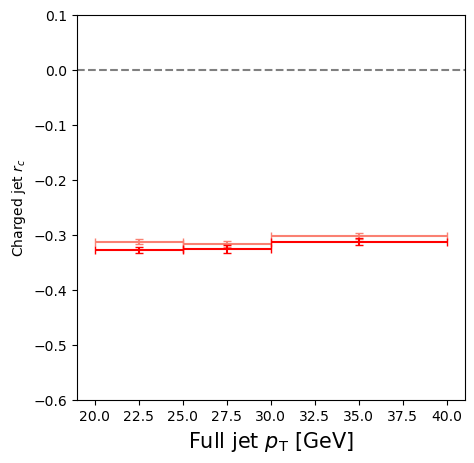

In [36]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='sample 1 corrected')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [37]:
rc_match_bs_vs_pt_array

[-0.334442297088895,
 -0.31280120973300135,
 -0.31670189827600975,
 -0.3018817785485725]

In [38]:
rc_err_match_bs_vs_pt_array

[0.005031472239405068,
 0.004843824846401325,
 0.005331678717212091,
 0.005230663600817661]

Check efficiency correction is not needed

In [39]:
df_alltruth_pt_array = [ df_alltruth[(df_alltruth.pt>15) & (df_alltruth.pt<20)],\
                       df_alltruth[(df_alltruth.pt>20) & (df_alltruth.pt<25)],\
                       df_alltruth[(df_alltruth.pt>25) & (df_alltruth.pt<30)],\
                       df_alltruth[(df_alltruth.pt>30) & (df_alltruth.pt<40)] ]

In [40]:
rc_alltruth_b_vs_pt_array = []
rc_err_alltruth_b_vs_pt_array = []
for i in range(0, len(df_alltruth_pt_array)):
    rc_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[0])
    rc_err_alltruth_b_vs_pt_array.append(getRcAndErr(df_alltruth_pt_array[i], 'b')[1])

In [41]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

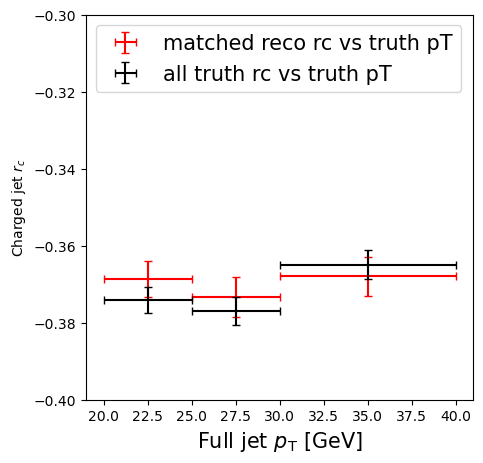

In [44]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='r', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_alltruth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_alltruth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='all truth rc vs truth pT')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.4,-0.3)
plt.legend(loc='upper left', fontsize=15)